# 04 · Scorecard — how do NM hospitals perform?

Question 1. One row per hospital across the three quality domains, using CMS's own
"compared to national" rollups (how many measures in each domain a hospital is Better /
No Different / Worse than the national rate), plus the overall star and the HCAHPS
patient-experience star.

We use CMS's rollups rather than inventing an aggregate, so nothing here is a number we
made up.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.viz import apply_style, BETTER, WORSE, NO_DIFFERENT, CATEGORICAL, INK2, SURFACE
apply_style()

INTERIM = Path("../data/interim")
PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")

# interim hospital file has the CMS domain rollup counts; processed hospitals.csv has
# the joined rural/urban group (added in the RUCA step, after the interim save).
hi = pd.read_csv(INTERIM / "hospital_information_nm.csv",
                 dtype={"Facility ID": str}, keep_default_na=False)
hospitals = pd.read_csv(PROCESSED / "hospitals.csv",
                        dtype={"facility_id": str}).set_index("facility_id")
hcahps = pd.read_csv(INTERIM / "hcahps_nm.csv", dtype={"Facility ID": str})
print("hospitals:", len(hi))

hospitals: 45


## 1) Build the per-hospital scorecard

Convert the CMS domain counts to numbers (blank / "Not Available" → missing, meaning the
hospital was not measured in that domain), and attach the HCAHPS summary star.

In [2]:
def num(col):
    return pd.to_numeric(hi[col], errors="coerce")

hcahps_star = (
    hcahps[hcahps["HCAHPS Measure ID"] == "H_STAR_RATING"]
    .set_index("Facility ID")["value"]
)

scorecard = pd.DataFrame({
    "facility_id": hi["Facility ID"],
    "facility_name": hi["Facility Name"],
    "overall_star": num("overall_rating"),
    "readm_better": num("Count of READM Measures Better"),
    "readm_no_different": num("Count of READM Measures No Different"),
    "readm_worse": num("Count of READM Measures Worse"),
    "mort_better": num("Count of MORT Measures Better"),
    "mort_no_different": num("Count of MORT Measures No Different"),
    "mort_worse": num("Count of MORT Measures Worse"),
    "safety_better": num("Count of Safety Measures Better"),
    "safety_no_different": num("Count of Safety Measures No Different"),
    "safety_worse": num("Count of Safety Measures Worse"),
})
# rural/urban + critical-access from the joined hospital table
scorecard["rural_urban"] = scorecard["facility_id"].map(hospitals["rural_urban"])
scorecard["is_critical_access"] = scorecard["facility_id"].map(hospitals["is_critical_access"])
scorecard["hcahps_star"] = scorecard["facility_id"].map(hcahps_star)

scorecard.to_csv(PROCESSED / "scorecard.csv", index=False)
print("Saved:", PROCESSED / "scorecard.csv", "|", len(scorecard), "rows")

rated = scorecard[scorecard["overall_star"].notna()].sort_values(
    "overall_star", ascending=False
)
display(rated[["facility_name", "rural_urban", "overall_star", "hcahps_star",
               "readm_worse", "mort_worse", "safety_worse"]].reset_index(drop=True))

Saved: ../data/processed/scorecard.csv | 45 rows


,facility_name,rural_urban,overall_star,hcahps_star,readm_worse,mort_worse,safety_worse
0,PRESBYTERIAN SANTA FE MEDICAL CENTER,metropolitan,5.0,3.0,0.0,0.0,0.0
1,LOVELACE WOMEN'S HOSPITAL,metropolitan,4.0,2.0,0.0,0.0,0.0
2,LOVELACE WESTSIDE HOSPITAL,metropolitan,4.0,3.0,0.0,0.0,0.0
3,CHRISTUS ST VINCENT REGIONAL MEDICAL CENTER,metropolitan,4.0,3.0,0.0,0.0,1.0
4,VA NEW MEXICO HEALTHCARE SYSTEM,metropolitan,3.0,4.0,2.0,0.0,1.0
5,COVENANT HEALTH HOBBS HOSPITAL,micropolitan,3.0,4.0,0.0,0.0,0.0
6,CHRISTUS SOUTHERN NEW MEXICO,micropolitan,3.0,3.0,1.0,0.0,0.0
7,THREE CROSSES REGIONAL HOSPITAL LLC,metropolitan,3.0,4.0,2.0,0.0,0.0
8,NORTHERN NAVAJO MEDICAL CENTER,small town,3.0,3.0,1.0,0.0,0.0
9,LINCOLN COUNTY MEDICAL CENTER,small town,2.0,4.0,2.0,0.0,0.0


## 2) How does NM compare to the national rate?

Totalling CMS's per-hospital verdicts across all NM hospitals, by domain.

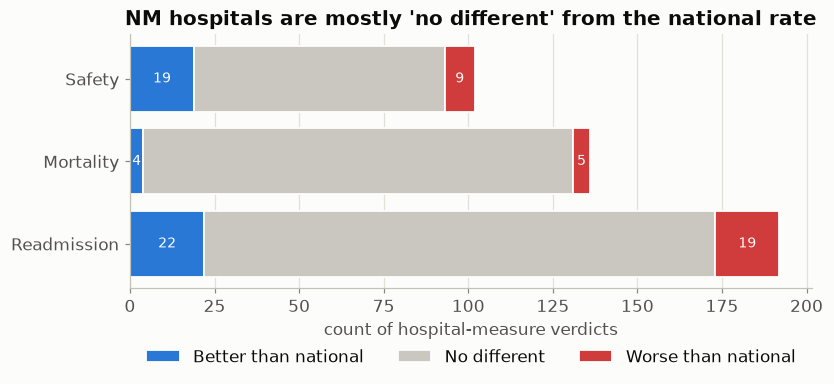

             Better  No Different  Worse
domain                                  
Readmission      22           151     19
Mortality         4           127      5
Safety           19            74      9


In [3]:
domains = {"Readmission": "readm", "Mortality": "mort", "Safety": "safety"}
rows = []
for label, pre in domains.items():
    rows.append((
        label,
        scorecard[f"{pre}_better"].sum(),
        scorecard[f"{pre}_no_different"].sum(),
        scorecard[f"{pre}_worse"].sum(),
    ))
d = pd.DataFrame(rows, columns=["domain", "Better", "No Different", "Worse"]).set_index("domain")

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.barh(d.index, d["Better"], color=BETTER, edgecolor=SURFACE, linewidth=1.2,
        label="Better than national")
ax.barh(d.index, d["No Different"], left=d["Better"], color=NO_DIFFERENT,
        edgecolor=SURFACE, linewidth=1.2, label="No different")
ax.barh(d.index, d["Worse"], left=d["Better"] + d["No Different"], color=WORSE,
        edgecolor=SURFACE, linewidth=1.2, label="Worse than national")
for i, (_, r) in enumerate(d.iterrows()):
    if r["Better"]:
        ax.text(r["Better"] / 2, i, int(r["Better"]), ha="center", va="center",
                color="white", fontsize=9)
    if r["Worse"]:
        ax.text(r["Better"] + r["No Different"] + r["Worse"] / 2, i, int(r["Worse"]),
                ha="center", va="center", color="white", fontsize=9)
ax.set_xlabel("count of hospital-measure verdicts")
ax.set_title("NM hospitals are mostly 'no different' from the national rate")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig_scorecard_vs_national.png")
plt.show()
print(d.astype(int))

## 3) Star rating distributions

The overall CMS star (23 rated hospitals) and the HCAHPS patient-experience star (26).

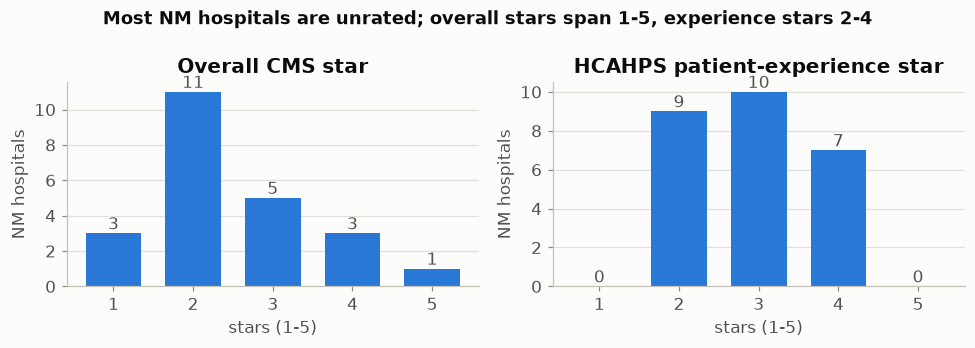

overall rated: 23 | hcahps rated: 26


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

for ax, col, title in [
    (axes[0], "overall_star", "Overall CMS star"),
    (axes[1], "hcahps_star", "HCAHPS patient-experience star"),
]:
    counts = scorecard[col].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    bars = ax.bar(counts.index.astype(int).astype(str), counts.values,
                  color=CATEGORICAL[0], width=0.7)
    ax.bar_label(bars, color=INK2)
    ax.set_title(title)
    ax.set_xlabel("stars (1-5)")
    ax.set_ylabel("NM hospitals")
    ax.grid(axis="x", visible=False)

fig.suptitle("Most NM hospitals are unrated; overall stars span 1-5, experience stars 2-4",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "fig_star_distributions.png")
plt.show()
print("overall rated:", int(scorecard["overall_star"].notna().sum()),
      "| hcahps rated:", int(scorecard["hcahps_star"].notna().sum()))

## Takeaway — scorecard (question 1)

- **Most verdicts are "no different than national."**
  - Readmission: 22 Better / 151 No Different / 19 Worse
  - Mortality: 4 / 127 / 5. 
  - Safety: 19 / 74 / 9
- NM hospitals rarely stand out either way on CMS measures.
- **Mortality is the only domain where Worse edges out Better** (5 vs 4). Readmission is
  near-even (22 Better / 19 Worse) but carries the most Worse verdicts in absolute count
  (19) and the measurable cost opportunity (notebook 06).
- **Stars: most hospitals are unrated** (22 of 45 have no overall star). Of the 23 rated:
  3 one-star, 11 two-star, 5 three-star, 3 four-star, 1 five-star (Presbyterian Santa Fe).
  HCAHPS experience stars run 2-4 (none 1 or 5).
- **But read this with notebook 03:** these verdicts exist only for the ~half of
  hospital-measures that are reported, concentrated in metro NM. The scorecard describes
  the hospitals CMS can measure, not all of New Mexico.